In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [7]:
House_data = pd.read_csv("HousePricePrediction.csv")

In [8]:
House_data

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2914,2914,160,RM,1936,Inside,Twnhs,7,1970,1970,CemntBd,0.0,546.0,NaN
2915,2915,160,RM,1894,Inside,TwnhsE,5,1970,1970,CemntBd,0.0,546.0,NaN
2916,2916,20,RL,20000,Inside,1Fam,7,1960,1996,VinylSd,0.0,1224.0,NaN
2917,2917,85,RL,10441,Inside,1Fam,5,1992,1992,HdBoard,0.0,912.0,NaN


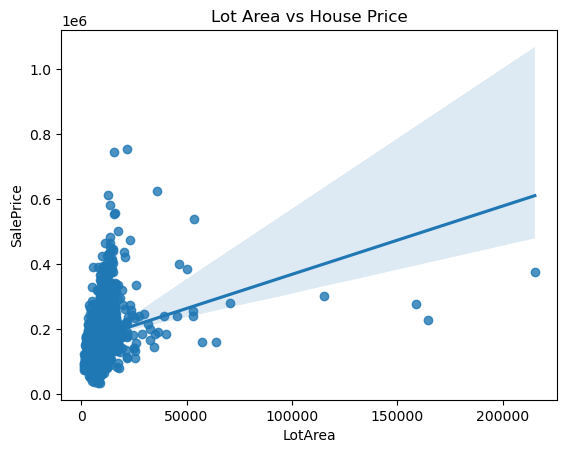

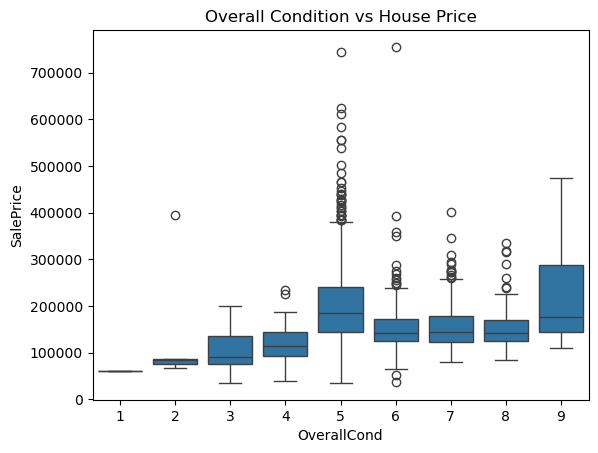

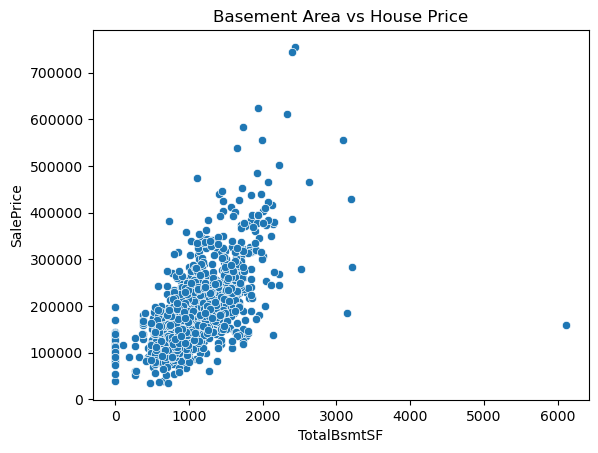

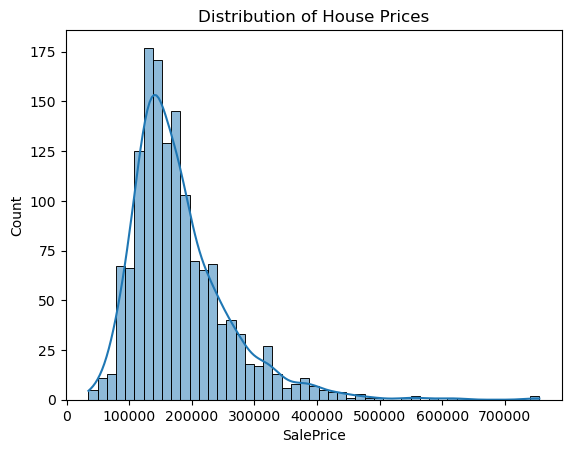

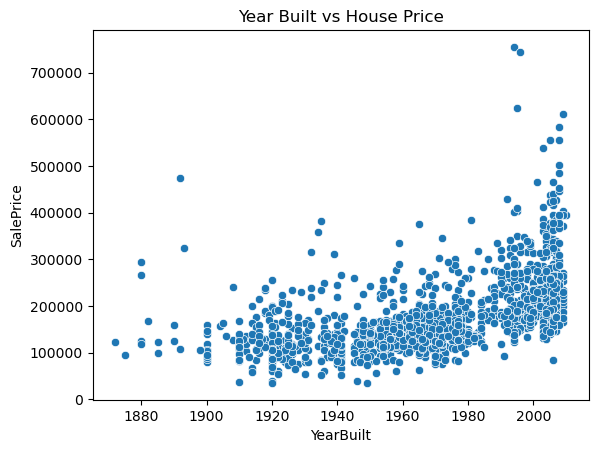

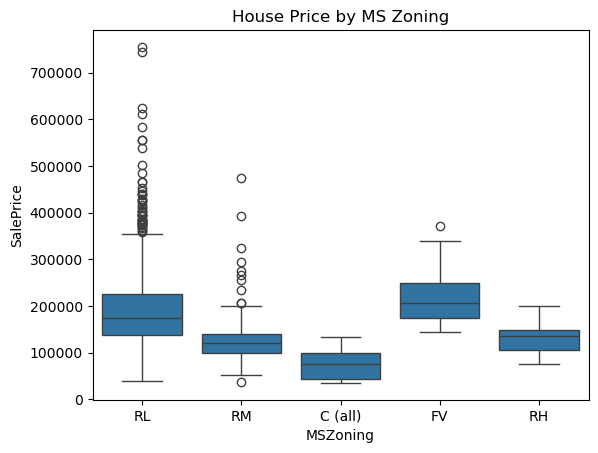

In [9]:
# 1. Lot Area vs House Price
sns.regplot(data=House_data, x="LotArea", y="SalePrice")
plt.title("Lot Area vs House Price")
plt.show()

# 2. Overall Condition vs House Price
sns.boxplot(data=House_data, x="OverallCond", y="SalePrice")
plt.title("Overall Condition vs House Price")
plt.show()

# 3. Basement Area vs House Price
sns.scatterplot(data=House_data, x="TotalBsmtSF", y="SalePrice")
plt.title("Basement Area vs House Price")
plt.show()

# 4. Distribution of House Prices
sns.histplot(data=House_data, x="SalePrice", kde=True)
plt.title("Distribution of House Prices")
plt.show()

# 5. Year Built vs House Price
sns.scatterplot(data=House_data, x="YearBuilt", y="SalePrice")
plt.title("Year Built vs House Price")
plt.show()

# 6. House Price by Zoning
sns.boxplot(data=House_data, x="MSZoning", y="SalePrice")
plt.title("House Price by MS Zoning")
plt.show()

In [9]:
House_data.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [11]:
House_data["SalePrice"]

0       208500.0
1       181500.0
2       223500.0
3       140000.0
4       250000.0
          ...   
2914         NaN
2915         NaN
2916         NaN
2917         NaN
2918         NaN
Name: SalePrice, Length: 2919, dtype: float64

In [12]:
House_data.isna()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2914,False,False,False,False,False,False,False,False,False,False,False,False,True
2915,False,False,False,False,False,False,False,False,False,False,False,False,True
2916,False,False,False,False,False,False,False,False,False,False,False,False,True
2917,False,False,False,False,False,False,False,False,False,False,False,False,True


In [84]:
House_data = House_data.fillna(House_data['SalePrice'].mean())

In [116]:
X = House_data.drop(columns=['SalePrice', 'Id'])
y = House_data['SalePrice']
cols = ['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st']
X = pd.get_dummies(X, columns=cols, drop_first=True)

In [117]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [118]:
X_train

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,MSZoning_FV,MSZoning_RH,MSZoning_RL,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
254,20,8400,6,1957,1957,0.0,1314.0,False,False,True,...,False,False,False,True,False,False,False,False,False,False
1066,60,7837,7,1993,1994,0.0,799.0,False,False,True,...,False,False,False,False,False,False,False,True,False,False
638,30,8777,7,1910,1950,0.0,796.0,False,False,True,...,False,False,False,True,False,False,False,False,False,False
799,50,7200,7,1937,1950,0.0,731.0,False,False,True,...,False,False,False,False,False,False,False,False,True,False
380,50,5000,6,1924,1950,0.0,1026.0,False,False,True,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095,20,9317,5,2006,2006,0.0,1314.0,False,False,True,...,False,False,False,False,False,False,False,True,False,False
1130,50,7804,3,1928,1950,0.0,1122.0,False,False,True,...,False,False,False,False,False,False,False,False,False,True
1294,20,8172,7,1955,1990,0.0,864.0,False,False,True,...,False,False,False,False,False,False,False,False,False,True
860,50,7642,8,1918,1998,0.0,912.0,False,False,True,...,False,False,False,False,False,False,False,False,True,False


In [119]:
y_train

254     145000.0
1066    178000.0
638      85000.0
799     175000.0
380     127000.0
          ...   
1095    176432.0
1130    135000.0
1294    115000.0
860     189950.0
1126    174000.0
Name: SalePrice, Length: 1168, dtype: float64

In [121]:
X_train["BsmtFinSF2"] = X_train["BsmtFinSF2"].fillna(X_train["BsmtFinSF2"].median())
X_train["TotalBsmtSF"] = X_train["TotalBsmtSF"].fillna(X_train["TotalBsmtSF"].median())

In [122]:
X_train

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,MSZoning_FV,MSZoning_RH,MSZoning_RL,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
254,20,8400,6,1957,1957,0.0,1314.0,False,False,True,...,False,False,False,True,False,False,False,False,False,False
1066,60,7837,7,1993,1994,0.0,799.0,False,False,True,...,False,False,False,False,False,False,False,True,False,False
638,30,8777,7,1910,1950,0.0,796.0,False,False,True,...,False,False,False,True,False,False,False,False,False,False
799,50,7200,7,1937,1950,0.0,731.0,False,False,True,...,False,False,False,False,False,False,False,False,True,False
380,50,5000,6,1924,1950,0.0,1026.0,False,False,True,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095,20,9317,5,2006,2006,0.0,1314.0,False,False,True,...,False,False,False,False,False,False,False,True,False,False
1130,50,7804,3,1928,1950,0.0,1122.0,False,False,True,...,False,False,False,False,False,False,False,False,False,True
1294,20,8172,7,1955,1990,0.0,864.0,False,False,True,...,False,False,False,False,False,False,False,False,False,True
860,50,7642,8,1918,1998,0.0,912.0,False,False,True,...,False,False,False,False,False,False,False,False,True,False


In [123]:
y_train

254     145000.0
1066    178000.0
638      85000.0
799     175000.0
380     127000.0
          ...   
1095    176432.0
1130    135000.0
1294    115000.0
860     189950.0
1126    174000.0
Name: SalePrice, Length: 1168, dtype: float64

In [124]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [125]:
y_pred = model.predict(X_test)

In [126]:
y_pred

array([168844.20187047, 243627.93266265, 114499.46802618, 157672.74928536,
       254809.72691561, 156499.8871421 , 177912.63550294, 127514.41651571,
       133133.47244362, 149402.60951095, 130794.50236615, 123245.60221165,
        80364.27242006, 239205.09970653, 218458.40576163, 177909.93322611,
       217597.00518371, 179150.77327368, 135680.39694335, 232757.15292119,
       163631.47385299, 219363.09382647, 202562.61369718, 154850.31244008,
       223837.5082334 , 166839.82458248, 228156.71441651, 110537.33765989,
       215037.51335144, 205629.10183973, 115051.49676838, 231549.64641402,
       224622.45132015, 128364.14241412, 251497.647427  , 140828.28483852,
       170989.33623262, 217385.70991952, 255132.48015839,  77807.51078478,
       118583.69813312, 217906.68251221, 125596.27931998, 291090.36797416,
       141473.52251816, 105135.34718202, 128070.20017547, 130672.55127484,
       320648.92241053, 146484.93143581, 112112.92648901, 193792.29031155,
       123203.44465367, 2

In [127]:
y_test

892     154500.0
1105    325000.0
413     115000.0
522     159000.0
1036    315500.0
          ...   
479      89471.0
1361    260000.0
802     189000.0
651     108000.0
722     124500.0
Name: SalePrice, Length: 292, dtype: float64

In [128]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test,y_pred)
print("r-sqaured: ",r2)
n=X_test.shape[0]
p=X_test.shape[1]
adjusted_r2 = 1-((1-r2)*(n-1)/(n-p-1))
print("adjusted_r2: ",adjusted_r2)

r-sqaured:  0.6195131796544853
adjusted_r2:  0.5708462607730822


(292, 33)